# Bike-Sharing Demand Forecasting: Day-Ahead Hourly Forecasts for Fleet Rebalancing

**Business question.** A bike-sharing operator (Capital Bikeshare, Washington D.C.) moves bikes between stations by truck and
schedules staff a day ahead. **How many bikes will be rented in each hour of tomorrow?** Under-forecasting leaves stations empty;
over-forecasting wastes truck and staff hours.

**Data.** UCI *Bike Sharing* dataset: 17,379 hourly records, 2011–2012, with rentals plus calendar and weather.

**Approach**
1. Explore the demand patterns (hour × day type, weather, growth trend)
2. Build **day-ahead features**: only information available by midnight the day before (lags of 24h+, calendar, weather)
3. Time-based split: train Jan 2011 – Aug 2012, test **Sep – Dec 2012** (never shuffled)
4. Compare against honest baselines (same hour last week; hour × day-type average)
5. Ridge regression vs gradient boosting (Poisson loss), tuned with rolling-origin cross-validation
6. A P90 quantile model for safety stock, checked for coverage

In [1]:
import sys

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.append("../src")
from style import C, apply_style, save

apply_style()
SEED = 42

## 1. Load and check

In [2]:
df = pd.read_csv("../data/raw/hour.csv")
df["ts"] = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")
df = df.sort_values("ts").reset_index(drop=True)
full_hours = pd.date_range(df.ts.min(), df.ts.max(), freq="h")
print(f"Rows: {len(df):,} | expected hours: {len(full_hours):,} | missing hours: {len(full_hours) - len(df)}")
print(f"Hourly rentals: mean {df.cnt.mean():.0f}, median {df.cnt.median():.0f}, max {df.cnt.max()}")

Rows: 17,379 | expected hours: 17,544 | missing hours: 165
Hourly rentals: mean 189, median 142, max 977


165 hours are missing (mostly overnight hours with no rentals and a few system outages). Rows are **not** filled in;
lag features are looked up by timestamp, so a missing hour simply gives a missing lag, which gradient boosting handles natively.

## 2. Demand patterns

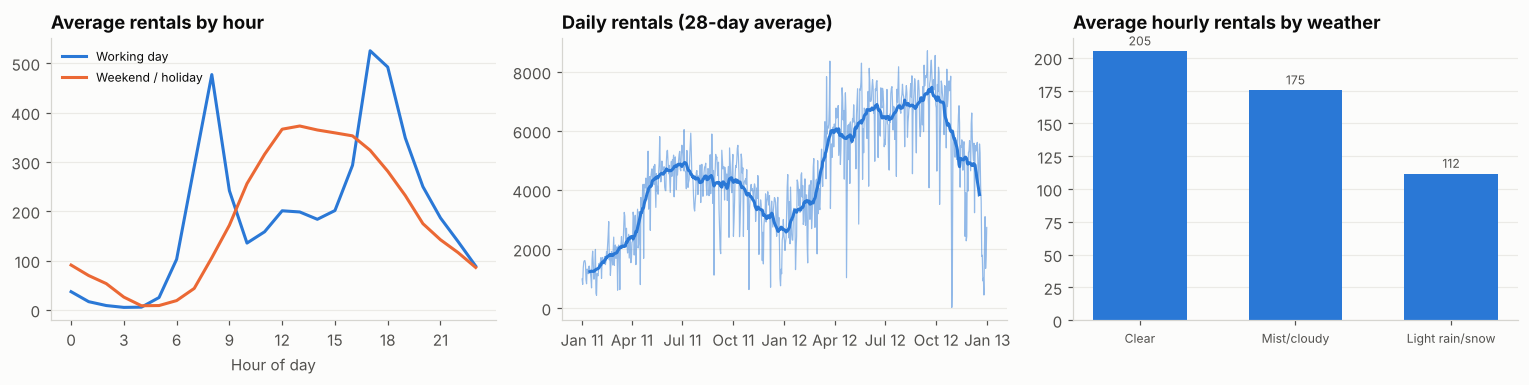

Rentals grew 65% from 2011 to 2012; weather 'clear' hours average 205 rentals vs 112 in light rain.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
prof = df.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
axes[0].plot(prof.index, prof[1], color=C["blue"], label="Working day")
axes[0].plot(prof.index, prof[0], color=C["orange"], label="Weekend / holiday")
axes[0].set_title("Average rentals by hour"); axes[0].set_xlabel("Hour of day"); axes[0].legend(fontsize=8)
axes[0].set_xticks(range(0, 24, 3))

daily = df.groupby("dteday")["cnt"].sum()
daily.index = pd.to_datetime(daily.index)
axes[1].plot(daily.index, daily.values, color=C["blue"], lw=0.8, alpha=0.5)
axes[1].plot(daily.rolling(28, center=True).mean(), color=C["blue"], lw=2)
axes[1].set_title("Daily rentals (28-day average)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

w = df.groupby("weathersit")["cnt"].agg(["mean", "size"])
w = w.loc[w["size"] >= 100, "mean"]  # "heavy rain" has only 3 hours, too few to show
labels = {1: "Clear", 2: "Mist/cloudy", 3: "Light rain/snow", 4: "Heavy rain"}
bars = axes[2].bar([labels[i] for i in w.index], w.values, color=C["blue"], width=0.6)
axes[2].bar_label(bars, labels=[f"{v:.0f}" for v in w.values], padding=2, fontsize=8, color=C["ink2"])
axes[2].set_title("Average hourly rentals by weather")
axes[2].tick_params(axis="x", labelsize=8)
save(fig, "01_demand_patterns")
plt.show()
yoy = df[df.yr == 1].cnt.sum() / df[df.yr == 0].cnt.sum() - 1
print(f"Rentals grew {yoy:.0%} from 2011 to 2012; weather 'clear' hours average {w.loc[1]:.0f} rentals vs {w.loc[3]:.0f} in light rain.")

Working days have two commuter peaks (8am and 5–6pm); weekends have one broad midday peak. Demand grew strongly year on
year and drops sharply in rain, so the model needs calendar, weather and a way to track the level (lags).

## 3. Day-ahead features
At midnight we forecast all 24 hours of the next day, so every demand feature must be at least **24 hours old**.

In [4]:
s = df.set_index("ts")["cnt"]
for lag in (24, 48, 168):
    df[f"lag_{lag}h"] = df["ts"].sub(pd.Timedelta(hours=lag)).map(s)
df["same_hour_7d_mean"] = pd.concat([df["ts"].sub(pd.Timedelta(days=d)).map(s) for d in range(1, 8)], axis=1).mean(axis=1)
day_total = df.groupby(df["ts"].dt.normalize())["cnt"].sum()
df["yesterday_total"] = (df["ts"].dt.normalize() - pd.Timedelta(days=1)).map(day_total)
df["trend_days"] = (df["ts"] - df["ts"].min()).dt.days

calendar = ["hr", "weekday", "workingday", "holiday", "mnth", "season"]
weather = ["weathersit", "temp", "atemp", "hum", "windspeed"]
lags = ["lag_24h", "lag_48h", "lag_168h", "same_hour_7d_mean", "yesterday_total", "trend_days"]
features = calendar + weather + lags
df[["ts", "cnt"] + lags].dropna().head()

,ts,cnt,lag_24h,lag_48h,lag_168h,same_hour_7d_mean,yesterday_total,trend_days
161,2011-01-08 00:00:00,25,17.0,11.0,16.0,11.000000,1510.0,7
162,2011-01-08 01:00:00,16,7.0,4.0,40.0,11.142857,1510.0,7
163,2011-01-08 02:00:00,16,1.0,2.0,32.0,7.833333,1510.0,7
165,2011-01-08 04:00:00,1,1.0,1.0,1.0,1.571429,1510.0,7
166,2011-01-08 05:00:00,5,5.0,4.0,1.0,3.333333,1510.0,7


## 4. Time-based train / test split

In [5]:
SPLIT = pd.Timestamp("2012-09-01")
data = df[df["ts"] >= df["ts"].min() + pd.Timedelta(days=7)].copy()  # first week has no 7-day history
train, test = data[data.ts < SPLIT], data[data.ts >= SPLIT]
X_train, y_train, X_test, y_test = train[features], train["cnt"], test[features], test["cnt"]
print(f"Train: {train.ts.min():%d %b %Y} – {train.ts.max():%d %b %Y} ({len(train):,} hours)")
print(f"Test:  {test.ts.min():%d %b %Y} – {test.ts.max():%d %b %Y} ({len(test):,} hours)")


def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "WAPE": np.abs(y_true - y_pred).sum() / y_true.sum(), "R2": r2_score(y_true, y_pred)}

Train: 08 Jan 2011 – 31 Aug 2012 (14,330 hours)
Test:  01 Sep 2012 – 31 Dec 2012 (2,888 hours)


## 5. Baselines

In [6]:
results = {}
preds = {}
preds["Seasonal naive (same hour last week)"] = test["lag_168h"].fillna(test["same_hour_7d_mean"]).to_numpy()
profile = train.groupby(["workingday", "hr"])["cnt"].mean()
preds["Hour × day-type average"] = test.set_index(["workingday", "hr"]).index.map(profile).to_numpy()
for name, p in preds.items():
    results[name] = metrics(y_test, p)
pd.DataFrame(results).T.round(3)

,MAE,RMSE,WAPE,R2
Seasonal naive (same hour last week),68.212,115.811,0.284,0.717
Hour × day-type average,93.986,137.531,0.391,0.601


## 6. Models, tuned with rolling-origin cross-validation
`TimeSeriesSplit` always trains on the past and validates on the following block, so tuning never peeks at the future.

In [7]:
tscv = TimeSeriesSplit(n_splits=4, test_size=24 * 30)

ridge = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["hr", "weekday", "mnth", "season", "weathersit"]),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
         ["workingday", "holiday", "temp", "atemp", "hum", "windspeed"] + lags),
    ])),
    ("model", Ridge()),
])
ridge_search = GridSearchCV(ridge, {"model__alpha": [0.1, 1, 10, 100]}, cv=tscv,
                            scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)

gbm = HistGradientBoostingRegressor(loss="poisson", random_state=SEED, categorical_features=[features.index("weathersit")])
gbm_search = GridSearchCV(
    gbm, {"learning_rate": [0.05, 0.1], "max_iter": [300, 600], "max_leaf_nodes": [31, 63], "min_samples_leaf": [20, 50]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1,
).fit(X_train, y_train)
print(f"Ridge best alpha {ridge_search.best_params_} | CV MAE {-ridge_search.best_score_:.1f}")
print(f"GBM   best params {gbm_search.best_params_} | CV MAE {-gbm_search.best_score_:.1f}")

# Ablation: the same GBM without lag features (calendar + weather only)
gbm_nolag = HistGradientBoostingRegressor(loss="poisson", random_state=SEED, **gbm_search.best_params_,
                                          categorical_features=[(calendar + weather).index("weathersit")])
gbm_nolag.fit(train[calendar + weather], y_train)

preds["Ridge regression"] = np.clip(ridge_search.predict(X_test), 0, None)
preds["Gradient boosting (no lag features)"] = gbm_nolag.predict(test[calendar + weather])
preds["Gradient boosting (Poisson)"] = gbm_search.predict(X_test)
for name in ["Ridge regression", "Gradient boosting (no lag features)", "Gradient boosting (Poisson)"]:
    results[name] = metrics(y_test, preds[name])
res = pd.DataFrame(results).T
res.style.format({"MAE": "{:.1f}", "RMSE": "{:.1f}", "WAPE": "{:.1%}", "R2": "{:.3f}"})

Ridge best alpha {'model__alpha': 100} | CV MAE 58.1
GBM   best params {'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 31, 'min_samples_leaf': 50} | CV MAE 39.6


,MAE,RMSE,WAPE,R2
Seasonal naive (same hour last week),68.2,115.8,28.4%,0.717
Hour × day-type average,94.0,137.5,39.1%,0.601
Ridge regression,60.2,90.7,25.1%,0.826
Gradient boosting (no lag features),88.0,126.3,36.7%,0.663
Gradient boosting (Poisson),46.2,71.8,19.2%,0.891


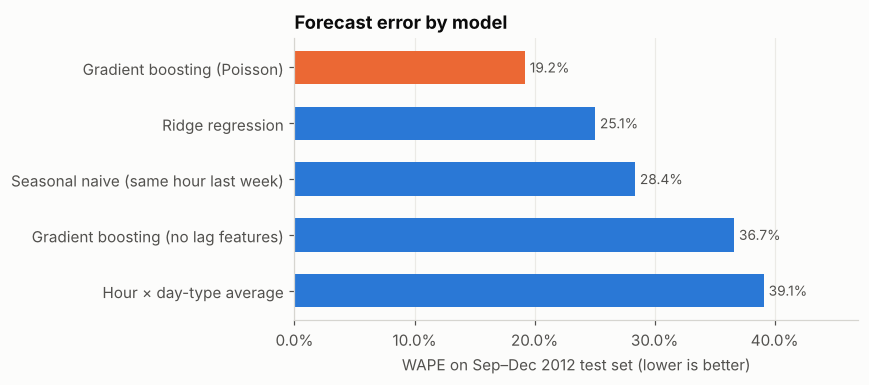

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
r = res.sort_values("WAPE", ascending=False)
bars = ax.barh(r.index, r["WAPE"], color=[C["orange"] if "Poisson" in i else C["blue"] for i in r.index], height=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in r["WAPE"]], padding=3, fontsize=9, color=C["ink2"])
ax.set_xlabel("WAPE on Sep–Dec 2012 test set (lower is better)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlim(0, r["WAPE"].max() * 1.2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Forecast error by model")
save(fig, "02_model_comparison")
plt.show()

## 7. How good is the best model, hour by hour?

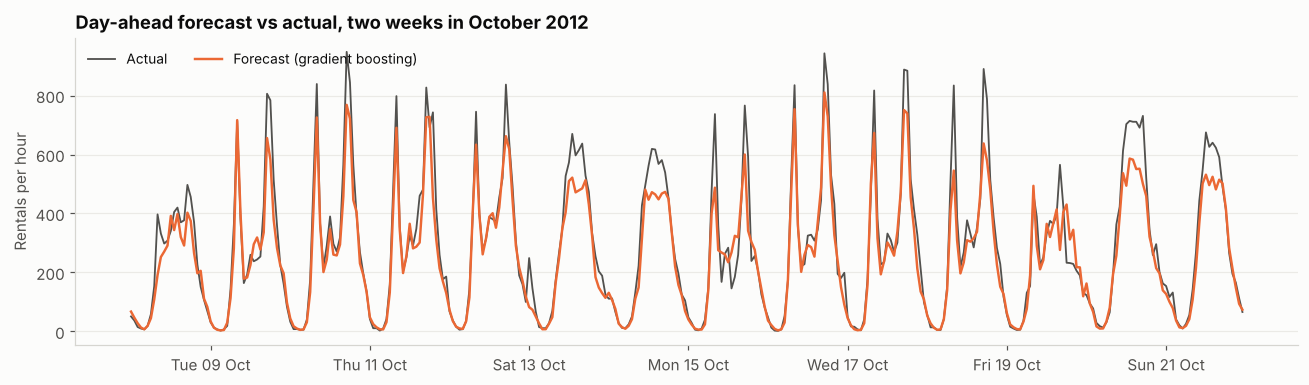

In [9]:
best = preds["Gradient boosting (Poisson)"]
window = (test.ts >= "2012-10-08") & (test.ts < "2012-10-22")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(test.loc[window, "ts"], y_test[window], color=C["ink2"], lw=1.2, label="Actual")
ax.plot(test.loc[window, "ts"], best[window.to_numpy()], color=C["orange"], lw=1.6, label="Forecast (gradient boosting)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
ax.set_ylabel("Rentals per hour")
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.set_title("Day-ahead forecast vs actual, two weeks in October 2012")
save(fig, "03_forecast_vs_actual")
plt.show()

In [10]:
err = test.assign(abs_err=np.abs(y_test - best), naive_err=np.abs(y_test - preds["Seasonal naive (same hour last week)"]))
by_hr = err.groupby("hr")[["abs_err", "naive_err", "cnt"]].mean()
peak = err[err.hr.isin([8, 17, 18]) & (err.workingday == 1)]
print(f"Commuter peaks (8am, 5-6pm on working days): mean demand {peak.cnt.mean():.0f}, model MAE {peak.abs_err.mean():.0f} "
      f"({peak.abs_err.sum() / peak.cnt.sum():.1%} WAPE) vs naive {peak.naive_err.mean():.0f}")

Commuter peaks (8am, 5-6pm on working days): mean demand 644, model MAE 124 (19.3% WAPE) vs naive 149


### Explainability: which features matter?

In [11]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(gbm_search.best_estimator_, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
pd.Series(perm.importances_mean, index=features).sort_values(ascending=False).head(8).rename("MAE increase when shuffled").round(1)

same_hour_7d_mean    62.1
hr                   40.5
workingday           18.0
temp                 14.1
lag_168h             12.2
hum                   9.5
lag_24h               7.5
weekday               6.0
Name: MAE increase when shuffled, dtype: float64

## 8. P90 forecast for safety stock
Rebalancing plans need an upper bound, not just the expected value. A quantile model (90th percentile) should give the number of
bikes that covers demand in 9 hours out of 10. **Coverage on the test set** shows whether that promise holds.

In [12]:
gbm_params = dict(gbm_search.best_params_)
cat_idx = [features.index("weathersit")]
q90_raw = HistGradientBoostingRegressor(loss="quantile", quantile=0.9, random_state=SEED, categorical_features=cat_idx, **gbm_params)
q90_raw.fit(X_train, y_train)
raw_cov = (y_test <= q90_raw.predict(X_test)).mean()
print(f"Raw P90 model: test coverage {raw_cov:.1%} (target 90%)")

Raw P90 model: test coverage 78.7% (target 90%)


The raw quantile model **under-covers**: demand kept growing in late 2012, so the test period sits above most of the training
data. The fix is **conformalised quantile regression**: hold out the last two months of training as a calibration block, measure
how far actual demand exceeds the P90 forecast there, and widen the bound by that amount.

In [13]:
CAL_START = pd.Timestamp("2012-07-01")
fit_part, cal_part = train[train.ts < CAL_START], train[train.ts >= CAL_START]
q90_fit = HistGradientBoostingRegressor(loss="quantile", quantile=0.9, random_state=SEED, categorical_features=cat_idx, **gbm_params)
q90_fit.fit(fit_part[features], fit_part["cnt"])
scores = cal_part["cnt"].to_numpy() - q90_fit.predict(cal_part[features])   # how much demand exceeded the bound
n_cal = len(scores)
adjust = np.quantile(scores, min(1.0, np.ceil((n_cal + 1) * 0.9) / n_cal))
p90 = q90_fit.predict(X_test) + adjust
coverage = (y_test <= p90).mean()
print(f"Calibration block: {cal_part.ts.min():%d %b} – {cal_part.ts.max():%d %b %Y} ({n_cal:,} hours); bound widened by {adjust:.0f} bikes")
print(f"Conformal P90: test coverage {coverage:.1%} (target 90%) | average buffer above point forecast {np.mean(p90 - best):.0f} bikes/hour")

Calibration block: 01 Jul – 31 Aug 2012 (1,488 hours); bound widened by 38 bikes
Conformal P90: test coverage 90.4% (target 90%) | average buffer above point forecast 96 bikes/hour


In [14]:
joblib.dump({"point_model": gbm_search.best_estimator_, "p90_model": q90_fit, "p90_adjustment": float(adjust), "features": features},
            "../models/demand_models.joblib")
print("Saved models/demand_models.joblib")

Saved models/demand_models.joblib


## 9. Summary

In [15]:
b, n, h = res.loc["Gradient boosting (Poisson)"], res.loc["Seasonal naive (same hour last week)"], res.loc["Hour × day-type average"]
nl = res.loc["Gradient boosting (no lag features)"]
print(f"""
- Test period Sep-Dec 2012 ({len(test):,} hours), day-ahead setting (all demand features at least 24h old).
- Gradient boosting (Poisson): MAE {b.MAE:.1f} bikes/hour, WAPE {b.WAPE:.1%}, R2 {b.R2:.3f}.
- vs seasonal naive WAPE {n.WAPE:.1%} ({1 - b.MAE / n.MAE:.0%} lower MAE) and hour x day-type average WAPE {h.WAPE:.1%}.
- Lag features matter: without them WAPE is {nl.WAPE:.1%}.
- P90 bound: raw quantile model covered only {raw_cov:.1%} of test hours; after conformal calibration {coverage:.1%} (target 90%).
""")


- Test period Sep-Dec 2012 (2,888 hours), day-ahead setting (all demand features at least 24h old).
- Gradient boosting (Poisson): MAE 46.2 bikes/hour, WAPE 19.2%, R2 0.891.
- vs seasonal naive WAPE 28.4% (32% lower MAE) and hour x day-type average WAPE 39.1%.
- Lag features matter: without them WAPE is 36.7%.
- P90 bound: raw quantile model covered only 78.7% of test hours; after conformal calibration 90.4% (target 90%).

